In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
df=pd.read_csv("Advertising.csv")

df.head()

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [5]:
df.shape

(200, 5)

In [6]:
df.columns

Index(['Unnamed: 0', 'TV', 'Radio', 'Newspaper', 'Sales'], dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   Radio       200 non-null    float64
 3   Newspaper   200 non-null    float64
 4   Sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


In [8]:
df.isnull().sum()

Unnamed: 0    0
TV            0
Radio         0
Newspaper     0
Sales         0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.describe

<bound method NDFrame.describe of      Unnamed: 0     TV  Radio  Newspaper  Sales
0             1  230.1   37.8       69.2   22.1
1             2   44.5   39.3       45.1   10.4
2             3   17.2   45.9       69.3    9.3
3             4  151.5   41.3       58.5   18.5
4             5  180.8   10.8       58.4   12.9
..          ...    ...    ...        ...    ...
195         196   38.2    3.7       13.8    7.6
196         197   94.2    4.9        8.1    9.7
197         198  177.0    9.3        6.4   12.8
198         199  283.6   42.0       66.2   25.5
199         200  232.1    8.6        8.7   13.4

[200 rows x 5 columns]>

In [13]:
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

df.columns = df.columns.str.strip()

df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


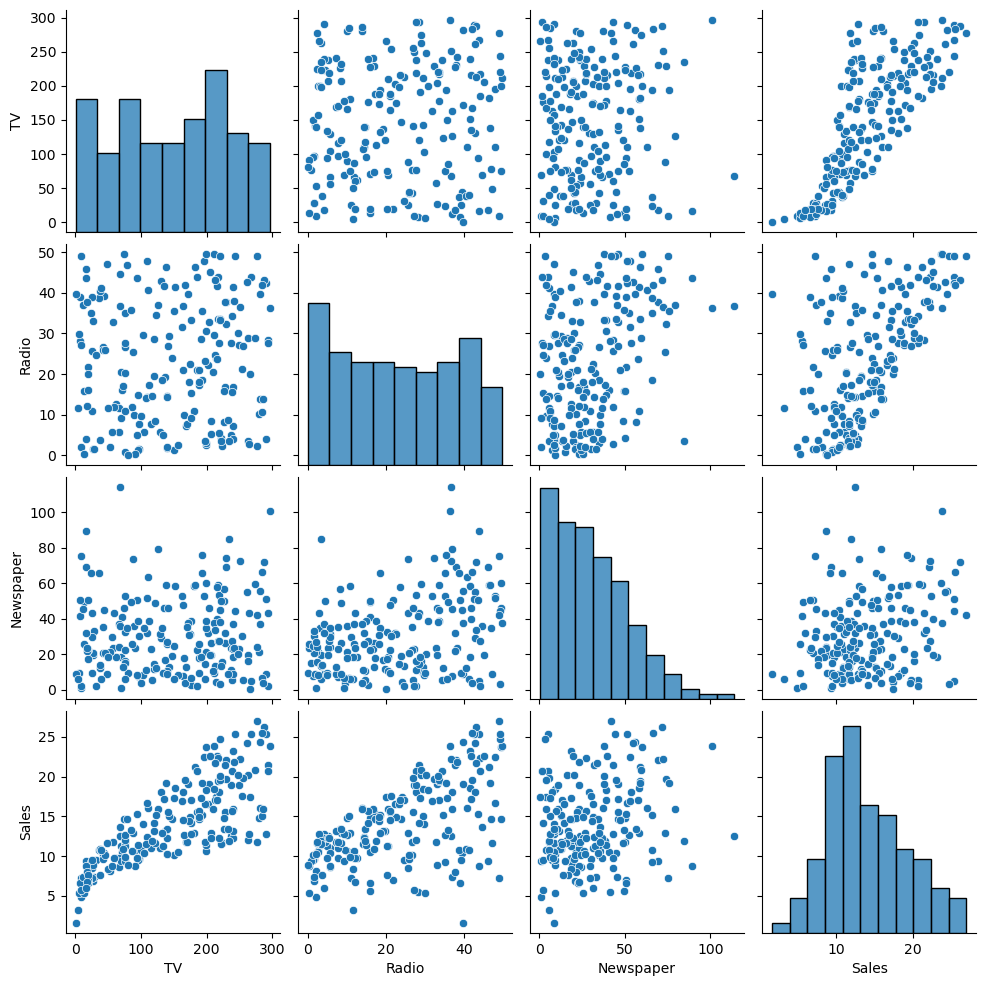

In [16]:
sns.pairplot(df)

plt.show()

 **Plot Sales vs TV advertising**

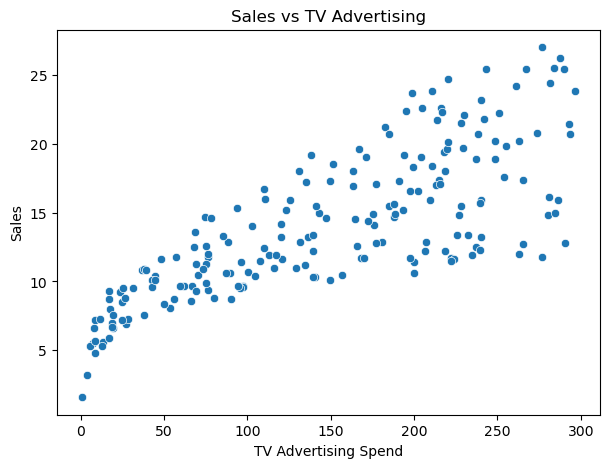

In [17]:
plt.figure(figsize=(7,5))

sns.scatterplot(data=df, x="TV", y="Sales")

plt.title("Sales vs TV Advertising")
plt.xlabel("TV Advertising Spend")
plt.ylabel("Sales")

plt.show()

 **Plot Sales vs Radio advertising**

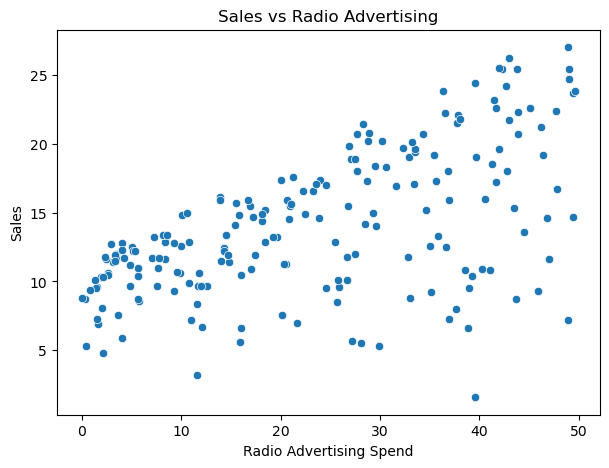

In [26]:
plt.figure(figsize=(7,5))

sns.scatterplot(data=df, x="Radio", y="Sales")

plt.title("Sales vs Radio Advertising")
plt.xlabel("Radio Advertising Spend")
plt.ylabel("Sales")

plt.show()

**Plot Sales vs Newspaper advertising**

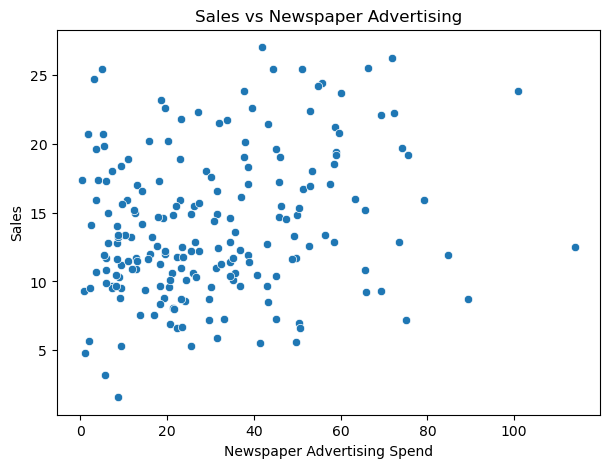

In [27]:
plt.figure(figsize=(7, 5))

sns.scatterplot(data=df, x="Newspaper", y="Sales")

plt.title("Sales vs Newspaper Advertising")
plt.xlabel("Newspaper Advertising Spend")
plt.ylabel("Sales")

plt.show()

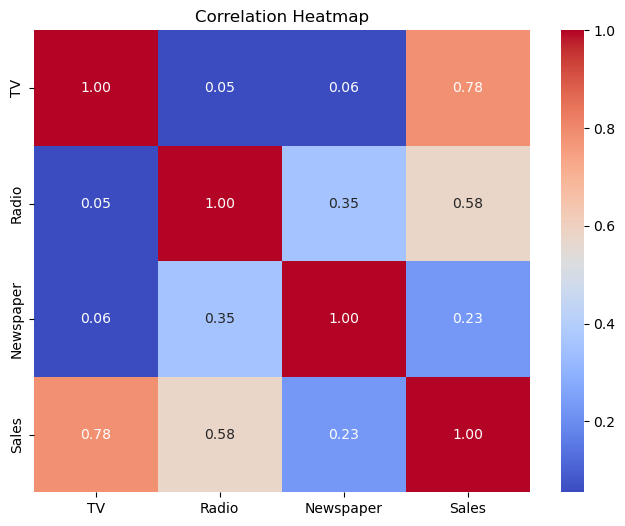

In [28]:
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [29]:
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (200, 3)
Target shape: (200,)


In [31]:
from sklearn.model_selection import train_test_split

X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (160, 3)
X_test: (40, 3)
y_train: (160,)
y_test: (40,)


In [33]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [34]:
y_pred_lr = lr_model.predict(X_test)

print("Actual Sales:")
print(y_test.head())

print("\nPredicted Sales:")
print(y_pred_lr[:5])

Actual Sales:
95     16.9
15     22.4
30     21.4
158     7.3
128    24.7
Name: Sales, dtype: float64

Predicted Sales:
[16.4080242  20.88988209 21.55384318 10.60850256 22.11237326]


In [35]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae_lr = mean_absolute_error(y_test, y_pred_lr)

rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression Results")
print("MAE:", mae_lr)
print("RMSE:", rmse_lr)
print("R2 Score:", r2_lr)

Linear Regression Results
MAE: 1.4607567168117606
RMSE: 1.7815996615334502
R2 Score: 0.899438024100912


In [36]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [37]:
y_pred_rf = rf_model.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

Random Forest Results
MAE: 0.6200999999999988
RMSE: 0.7685910811348248
R2 Score: 0.9812843792541843


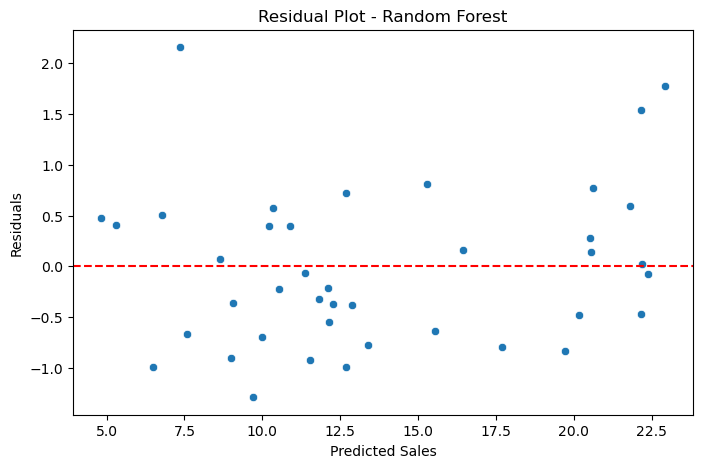

In [38]:
residuals = y_test - y_pred_rf

plt.figure(figsize=(8, 5))

sns.scatterplot(x=y_pred_rf, y=residuals)

plt.axhline(y=0, color="red", linestyle="--")

plt.title("Residual Plot - Random Forest")
plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")

plt.show()

In [39]:
importance = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

     Feature  Importance
0         TV    0.624810
1      Radio    0.362201
2  Newspaper    0.012989


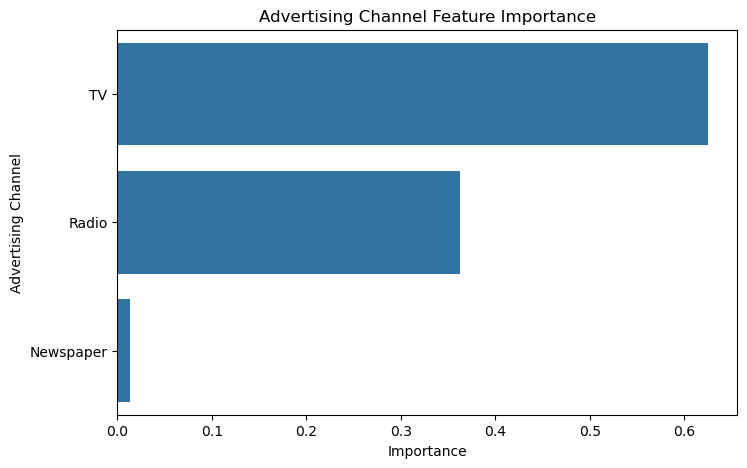

In [40]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Advertising Channel Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Advertising Channel")

plt.show()

In [41]:
print(feature_importance)

     Feature  Importance
0         TV    0.624810
1      Radio    0.362201
2  Newspaper    0.012989


## Conclusion

In this project, I developed a machine learning model to predict product sales using advertising expenditure on TV, Radio, and Newspaper.

I performed exploratory data analysis, visualized relationships between advertising channels and sales, and trained two regression models: Linear Regression and Random Forest Regressor.

The models were evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² score.

**Model comparison:**

* Linear Regression MAE: 1.461
* Linear Regression RMSE: 1.782
* Linear Regression R²: 0.8994
* Random Forest MAE: 0.620
* Random Forest RMSE: 0.769
* Random Forest R²: 0.9813

Random Forest performed better on the test set, achieving an R² score of approximately 98.13%.

Feature-importance analysis showed that TV advertising was the most influential feature in the Random Forest model, followed by Radio and Newspaper advertising.

This project demonstrates how Python and machine learning can be used to analyze advertising data and predict sales. The results describe predictive relationships in this dataset and do not establish that advertising expenditure directly causes changes in sales.
